# Lab 07: Genetic Algorithms

## Total: 50 points

In this lab, you'll explore the fundamentals of genetic algorithms by implementing core operations like selection, crossover, and mutation. We give you the initialization code and fitness function so you can focus the different ways to implement core operations.

## General Instructions

- Carefully read through the commented helper functions.
- Implement the missing functions where marked with `pass`.
- This lab is VERY open ended! There isn't one way to do this. Implement the strategies or verisons that interest you!
- **We have provided suggested parameters to pass into the unimplemented functions, but depending on the methods you pick, the parameters might change or you will need additional ones. Make sure to edit the parameter list for methods and strategies you use!!** 

In [208]:
import random
import matplotlib.pyplot as plt
import time

In [209]:
# Problem Constants
NUM_PEOPLE = 5
SHIFTS_PER_DAY = 3
DAYS_PER_WEEK = 7
SHIFTS_PER_WEEK = SHIFTS_PER_DAY * DAYS_PER_WEEK # 21

In [210]:
# GA Parameters
POPULATION_SIZE = 100       # Number of schedules in each generation
GENERATIONS = 150           # Number of generations to run
MUTATION_RATE = 0.02        # Probability of a single bit flip mutation
CROSSOVER_RATE = 0.7        # Probability that crossover occurs between two parents
HARD_PENALTY = -2           # Penalty per violated hard constraint
SOFT_PENALTY = -1           # Penalty per violated soft constraint

# Helper Functions

In [211]:
## Helper Functions
def get_shift_details(shift_index):
    """
    Calculates day (0-6) and shift type (0=M, 1=A, 2=N) from shift index (0-20).

    Args:
        shift_index (int): The shift index (0-20)

    Returns:
        day (int): The day of the week (0-6)
        shift_type (int): The shift type (0=M, 1=A, 2=N)
    """
    if not (0 <= shift_index < SHIFTS_PER_WEEK):
        raise ValueError(f"shift_index {shift_index} out of range [0, {SHIFTS_PER_WEEK-1}]")
    day = shift_index // SHIFTS_PER_DAY
    shift_type = shift_index % SHIFTS_PER_DAY
    return day, shift_type

def print_schedule(schedule, fitness):
    """
    Prints the schedule in a readable format.

    Args:
        schedule (list): The schedule to print
        fitness (float): The fitness score of the schedule
    """
    print(f"\nSchedule (Fitness: {fitness:.2f}):")
    days = ["Sun", "Mon", "Tue", "Wed", "Thu", "Fri", "Sat"]
    shifts = ["M", "A", "N"]
    header = "      " + " | ".join([days[d] for d in range(DAYS_PER_WEEK)])
    print(header)
    subheader = "      " + " ".join([f"{s}" for _ in days for s in shifts])
    print(subheader)
    print("      " + "-" * (len(subheader)-1))
    for person_idx, person_schedule in enumerate(schedule):
        schedule_str = ""
        for i in range(SHIFTS_PER_WEEK):
             schedule_str += str(person_schedule[i])
             if (i + 1) % SHIFTS_PER_DAY == 0 and i < SHIFTS_PER_WEEK - 1:
                 schedule_str += " " # Add space between days
        print(f"ATC {person_idx+1}: {schedule_str}")
    print("-" * (len(subheader) + 5))

def plot_fitness(fitness_history, avg_history):
    """
    Plots the best and average fitness score per generation.

    Args:
        fitness_history (list): A list of fitness scores for each generation

    Returns:
        None
    """
    plt.figure(figsize=(12, 6))
    generations = range(1, len(fitness_history) + 1)
    plt.plot(generations, fitness_history, marker='o', linestyle='-', label='Best Fitness')
    plt.plot(generations, avg_history, marker='o', linestyle='-', label='Average Fitness')
    plt.title('GA Fitness Progression for ATC Scheduling')
    plt.xlabel('Generation')
    plt.ylabel('Fitness Score (Higher is Better)')
    # Set y-limit to start slightly below the minimum fitness achieved or a reasonable lower bound
    min_fitness = min(fitness_history)
    plt.ylim(bottom=min(min_fitness - 5, -50)) # Adjust y-axis floor
    plt.legend()
    plt.grid(True)
    plt.show()

## Initialization

Helper code to create the initial population. Make sure you understand how we have chosen to represent the individual and population!

In [212]:
# Init GA
def generate_initial_representation(num_people, shifts_per_week):
  """
  Creates a single random schedule representation (chromosome).
  Each person gets a list of 0s and 1s for the week's shifts.

  Args:
    num_people (int): The number of people in the schedule.
    shifts_per_week (int): The number of shifts per week.

  Returns:
    schedule (list): A list of lists, where each inner list represents a person's schedule for the week.
  """
  schedule = []
  for _ in range(num_people):
    person_schedule = [random.choice([0, 1]) for _ in range(shifts_per_week)]
    schedule.append(person_schedule)
  return schedule

def generate_population(population_size, num_people, shifts_per_week):
  """ Creates the initial population of random schedules. """
  return [generate_initial_representation(num_people, shifts_per_week)
          for _ in range(population_size)]

## Fitness Function

Evaluate how close a candidate is to the target solution. Note how hard versus soft constraints are handled.

In [213]:
def evaluate_fitness(schedule, num_people, shifts_per_week, shifts_per_day):
    """ 
    Calculates the fitness of a single schedule based on constraints. 

    Args:
        schedule (list): The schedule to evaluate
        num_people (int): The number of people in the schedule
        shifts_per_week (int): The number of shifts per week
        shifts_per_day (int): The number of shifts per day

    Returns:
        fitness (float): The fitness score of the schedule
    """
    fitness = 0 # Start with perfect fitness, subtract penalties

    # Hard Constraint Checks

    # 1. Minimum controllers per shift
    min_controllers = {0: 1, 1: 2, 2: 1} # M:1, A:2, N:1
    shift_violations = 0
    for shift_idx in range(shifts_per_week):
        _, shift_type = get_shift_details(shift_idx)

        # Calculate number of controllers on this shift
        controllers_on_shift = sum(schedule[p][shift_idx] for p in range(num_people))
        required = min_controllers[shift_type]

        # Penalize for each missing controller
        if controllers_on_shift < required:
            fitness += HARD_PENALTY * (required - controllers_on_shift)
            shift_violations += (required - controllers_on_shift)

    # 2. Rest periods
    rest_violations = 0
    for p in range(num_people):
        for shift_idx in range(shifts_per_week):
            if schedule[p][shift_idx] == 1: # If person p works this shift
                _, shift_type = get_shift_details(shift_idx)

                # a) Rest after Morning (0) or Afternoon (1)
                if shift_type in [0, 1]:
                    next_shift_idx = shift_idx + 1
                    # Check boundary: ensure next shift is within the week
                    if next_shift_idx < shifts_per_week and schedule[p][next_shift_idx] == 1:
                         fitness += HARD_PENALTY # Violation: Working the very next shift
                         rest_violations += 1

                # b) Rest after Night (2)
                elif shift_type == 2:
                    # Check the next 3 shifts (full day)
                    violation_found_for_night_shift = False
                    for i in range(1, shifts_per_day + 1):
                        next_shift_idx = shift_idx + i
                        # Check boundary: ensure check stays within the week
                        if next_shift_idx < shifts_per_week and schedule[p][next_shift_idx] == 1:
                            if not violation_found_for_night_shift: # Only penalize once per night shift violation
                                fitness += HARD_PENALTY
                                rest_violations += 1
                                violation_found_for_night_shift = True
                            # No need to check further shifts for *this* night shift once violation is found

    # Soft Constraint Checks

    # 1. Excess controllers in tower
    excess_violations = 0
    for shift_idx in range(shifts_per_week):
        _, shift_type = get_shift_details(shift_idx)
        controllers_on_shift = sum(schedule[p][shift_idx] for p in range(num_people))
        required = min_controllers[shift_type]
        if controllers_on_shift > required:
            excess = controllers_on_shift - required
            fitness += SOFT_PENALTY * excess # Penalize for each extra controller
            excess_violations += excess

    # A fitness of 0 means no constraints were violated. Higher (less negative) is better.
    # You could also return the counts of violations for analysis if needed:
    # return fitness, shift_violations, rest_violations, excess_violations
    return fitness

## Q1.1 Parent Selection (4 points)

In this step, pick the parents chosen for crossover. Recall there are lots of different ways this can fit together with the crossover step. It's up to you on which method you pick.

In [214]:
def parent_selection(population, fitness_scores):
    """
    Selects parents using tournament selection (k=3).

    Args:
        population (list): A list of lists, where each inner list represents a candidate solutions/schedule.
        fitness_scores (list): A list of floats representing the fitness of each corresponding solution in `population`.

    Returns:
        selected_parents (list): A list of selected solutions to be used as parents for crossover.
    """
    selected_parents = []
    selected_indices = set()
    max_parents = 25
    k = 3

    while len(selected_parents) < max_parents:
        # Prevent selecting the same parent more than once
        available = [(i, solution) for i, solution in enumerate(population) if i not in selected_indices]
        if len(available) < k:
            break
        
        tournament = random.sample(available, k)
        best = max(tournament, key=lambda x: fitness_scores[x[0]])
        selected_parents.append(best[1])
        selected_indices.add(best[0])

    return selected_parents


## Q1.2 Crossover (4 points)

In this step, you combine two (or more) parent chromosomes to produce an offspring (or more). Recall that you can use the CROSSOVER_RATE parameter.

In [266]:
def crossover(parent_1, parent_2, num_people):
    """
    Performs controller-level crossover between two parents.

    Args:
        parent_1 (list): First parent selected for crossover.
        parent_2 (list): Second parent selected for crossover.
        num_people (int): The number of people in the schedule.

    Returns:
        child (list): New child solution.
    """
    child = [random.choice([parent_1[controller], parent_2[controller]])[:] for controller in range(num_people)]
    return child

## Q1.3 Mutation (4 points)

Add random mutations to chromosomes to maintain genetic diversity. You'll implement a function that randomly changes characters in the chromosome string. Recall that you can use the MUTATION_RATE parameter.

In [216]:
def mutate(schedule, mutation_rate):
    """
    Performs bit-flip mutations on the candidate solutions to maintain genetic diversity.

    Args:
        schedule (list): The original schedule to be mutated. Represents one solution.
        mutation_rate (float): Probability that any given bit in the schedule will be flipped.

    Returns:
        mutated (list): A possibly mutated version of the input schedule.
    """
    mutated = []
    for controller in schedule:
        new_schedule = []
        for shift in controller:
            if random.random() < mutation_rate:
                new_schedule.append(1 - shift) # Flip the bit
            else:
                new_schedule.append(shift)
        mutated.append(new_schedule)
    return mutated

## Q1.4 Selection (4 points)

You will implement a method for selecting parent chromosomes based on their fitness scores. The better the fitness, the higher the chance of selection.

In [217]:
def select_survivors(population, offspring_population, population_size, num_people, shifts_per_week, shifts_per_day):
    """
    Selects the next generation using (μ + λ) elitist strategy.
    
    Args:
        population (list): The current population of schedules.
        offspring_population (list): The newly created offspring schedules.
        population_size (int): The desired number of schedules to keep.
        num_people (int): Number of controllers in each schedule.
        shifts_per_week (int): Total number of shifts in a week.
        shifts_per_day (int): Number of shifts in a day.

    Returns:
        survivors (list): A list of the top `population_size` schedules selected for the next generation.
    """
    plus_strategy = population + offspring_population

    fitness_scores = [
        evaluate_fitness(schedule, num_people, shifts_per_week, shifts_per_day)
        for schedule in plus_strategy
    ]

    scored_population = list(zip(plus_strategy, fitness_scores))

    # Sort by fitness in descending order
    sorted_population = sorted(scored_population, key=lambda x: x[1], reverse=True)

    survivors = [schedule for schedule, _ in sorted_population[:population_size]]
    survivor_fitness_scores = [fitness for _, fitness in sorted_population[:population_size]]

    return survivors, survivor_fitness_scores

## Q1.5 Putting It All Together (4 points)

Finally, integrate all components into a loop to simulate multiple generations of evolution.

In [ ]:
def genetic_algorithm(population_size, num_people, shifts_per_week, shifts_per_day,
                      generations, mutation_rate):
    """
    Runs a genetic algorithm to evolve work schedules over multiple generations.

    Args:
        population_size (int): Number of schedules in the population.
        num_people (int): Number of controllers in each schedule.
        shifts_per_week (int): Number of shifts in a week.
        shifts_per_day (int): Number of shifts per day.
        generations (int): Number of generations to run the algorithm.
        mutation_rate (float): Probability that any given bit in a schedule will be flipped.

    Returns:
        best_schedule (list): The best schedule found.
        best_fitness (float): Fitness score of the best schedule.
        best_fit_hist (list): Best fitness scores recorded across generations.
        avg_fit_hist (list): Average fitness scores recorded across generations.
    """

    best_fit_hist = []
    avg_fit_hist = []

    # Initialize population
    population = generate_population(population_size, num_people, shifts_per_week)

    curr_gen = 0
    while curr_gen < generations:
        # Evaluate fitness of each schedule
        fitness_scores = [
            evaluate_fitness(schedule, num_people, shifts_per_week, shifts_per_day)
            for schedule in population
        ]

        # Select parents
        selected_parents = parent_selection(population, fitness_scores)

        # Crossover to create offspring
        offspring = []
        num_offspring = 100

        while len(offspring) < num_offspring:
            parent_1, parent_2 = random.sample(selected_parents, 2)
            child = crossover(parent_1, parent_2, num_people)
            offspring.append(child)

        # Mutation of offspring
        mutated_offspring = [
            mutate(schedule, mutation_rate)
            for schedule in offspring
        ]

        # Survival selection
        population, population_fitness = select_survivors(population, mutated_offspring, population_size, num_people, shifts_per_week, shifts_per_day)

        best_fit_hist.append(population_fitness[0])
        avg_fit_hist.append(sum(population_fitness) / len(population_fitness))

        curr_gen += 1

    return population[0], population_fitness[0], best_fit_hist, avg_fit_hist

# Main

Run the genetic algorithm and plot the fitness scores.


      Best Schedule Found

Schedule (Fitness: 0.00):
      Sun | Mon | Tue | Wed | Thu | Fri | Sat
      M A N M A N M A N M A N M A N M A N M A N
      ----------------------------------------------
ATC 1: 010 010 010 001 000 010 001
ATC 2: 000 100 100 010 101 000 010
ATC 3: 100 010 010 010 000 101 000
ATC 4: 010 001 000 100 010 000 100
ATC 5: 001 000 001 000 010 010 010
----------------------------------------------------


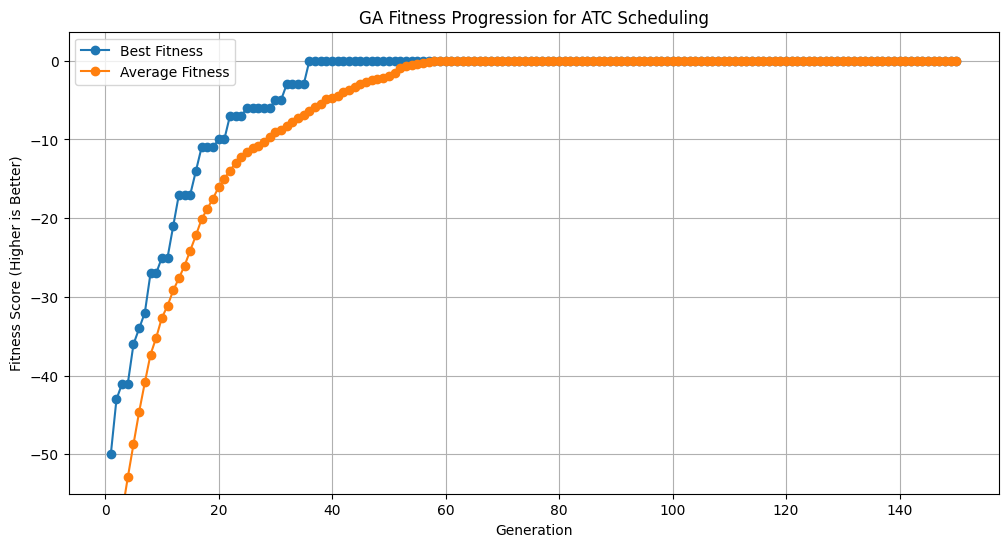

In [221]:
best_schedule, best_fitness, history, avg_history = genetic_algorithm(
        population_size=POPULATION_SIZE,
        num_people=NUM_PEOPLE,
        shifts_per_week=SHIFTS_PER_WEEK,
        shifts_per_day=SHIFTS_PER_DAY,
        generations=GENERATIONS,
        mutation_rate=MUTATION_RATE,
    ) # CHECK THE PARAMETERS!!!

print("\n" + "="*30)
print("      Best Schedule Found")
print("="*30)
if best_schedule:
    # Evaluate the final best schedule again to be certain of its fitness score
    final_check_fitness = evaluate_fitness(best_schedule, NUM_PEOPLE, SHIFTS_PER_WEEK, SHIFTS_PER_DAY)
    print_schedule(best_schedule, final_check_fitness)
    if abs(final_check_fitness - best_fitness) > 0.01:
            print(f"[Note] Final re-evaluated fitness {final_check_fitness:.2f} differs slightly from tracked fitness {best_fitness:.2f}")
else:
    print("\nNo suitable schedule found (best_schedule is None).")
    # Explain and show the plot
    print("\n" + "="*30)
    print("      Fitness Plot Explanation")
    print("="*30)
    print("The plot shows the fitness score evolution over generations:")
    print(" - 'Best Fitness': The fitness score of the absolute best schedule found in each generation.")
    print(" - 'Average Fitness': The average fitness score of all schedules in the population for each generation.")
    print("Ideally, both lines should trend upwards (towards 0 or positive values).")
    print("The gap between average and best fitness indicates population diversity.")
plot_fitness(history, avg_history)

# Q2 Exploring the Solution Space (5 points)

Now that you've written a base genetic algorithm, let's see what additional information you can learn about this problem. Every air traffic controller gets paid the same amount regardless of how many shifts they work. Management wants to find the minimum number of air traffic controllers they need without creating ANY constraint violations.

a. Using your genetic algorithm solver, find the minimum number of air traffic controllers needed.

b. Describe how you came up with your answer to part A and how confident you are in that answer.

# Solution 2

a. Minimum number of controllers needed with no violations: 4

b. I increased the number of generations in the simulation from 150 to 500, to ensure that we reached a maximum for the fitness score. I then ran a parameter sweep for the number of controllers in the simulation. I made it so that the sweep would stop once it reached a satisfying solution, and had the program report the number of controllers in that satisfactory simulation. However, I can't be 100% confident this is correct, seeing as the earlier simulations with a smaller number of controllers might not have had enough generations to converge or got trapped in a local maximum that did not result in a fitness score of 0.

In [280]:
min_controllers = None

for num_controllers in range(1, NUM_PEOPLE + 1):
    best_schedule, best_fitness, _, _ = genetic_algorithm(
        population_size=POPULATION_SIZE,
        num_people=num_controllers,
        shifts_per_week=SHIFTS_PER_WEEK,
        shifts_per_day=SHIFTS_PER_DAY,
        generations=500,
        mutation_rate=MUTATION_RATE,
    )

    if best_fitness == 0:
        min_controllers = num_controllers
        break

print(f"Minimum number of controllers needed with no violations: {min_controllers}")


Minimum number of controllers needed with no violations: 4


# Q3 Tweaking the Parameters (10 points)

Now that you've written a base genetic algorithm, let's see if you can improve the performance by tweaking the parameters. Pick one of the GA Parameters and create a plot showing the results at different values.


      Best Mutation Rate(s) Found
Best fitness score: 0.0000
Best mutation rate(s): 0.0200, 0.0250, 0.0300


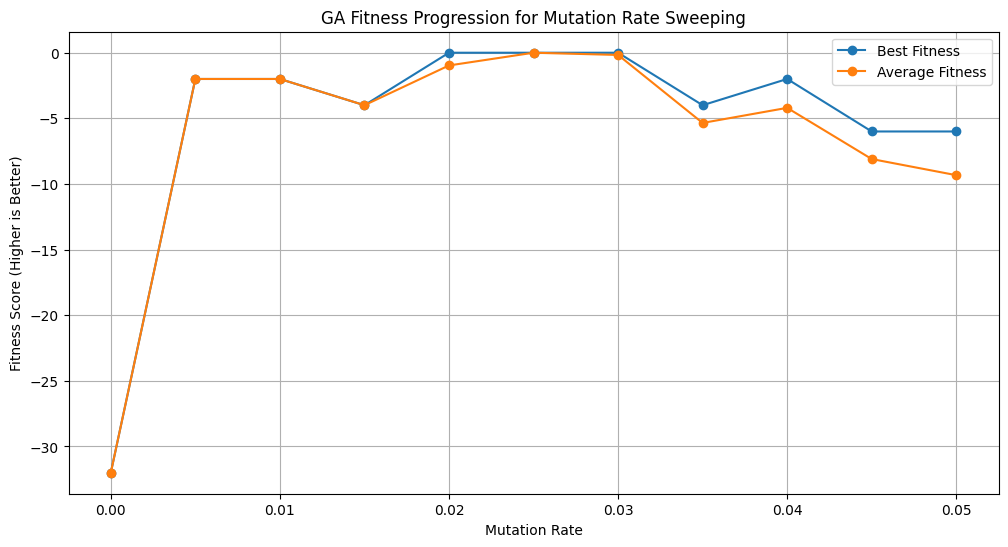

In [234]:
def float_range(start, stop, step):
    """Generates a list of floats within the given range."""
    result = []
    current = start
    while current < stop:
        result.append(current)
        current += step
    return result

mutation_rates = float_range(0, 0.05, 0.005)
best_fitnesses = []
avg_fitnesses = []

for rate in mutation_rates:
    best_schedule, best_fitness, history, avg_history = genetic_algorithm(
        population_size=POPULATION_SIZE,
        num_people=NUM_PEOPLE,
        shifts_per_week=SHIFTS_PER_WEEK,
        shifts_per_day=SHIFTS_PER_DAY,
        generations=GENERATIONS,
        mutation_rate=rate,
    )
    best_fitnesses.append(best_fitness)
    avg_fitnesses.append(avg_history[-1])

# Find all mutation rates with the max fitness score
max_fitness = max(best_fitnesses)
best_rates = [rate for rate, fitness in zip(mutation_rates, best_fitnesses) if fitness == max_fitness]

print("\n" + "="*30)
print("      Best Mutation Rate(s) Found")
print("="*30)
print(f"Best fitness score: {max_fitness:.4f}")
print("Best mutation rate(s):", ", ".join(f"{rate:.4f}" for rate in best_rates))

# Plot sweep
plt.figure(figsize=(12, 6))
plt.plot(mutation_rates, best_fitnesses, marker='o', linestyle='-', label='Best Fitness')
plt.plot(mutation_rates, avg_fitnesses, marker='o', linestyle='-', label='Average Fitness')
plt.title('GA Fitness Progression for Mutation Rate Sweeping')
plt.xlabel('Mutation Rate')
plt.ylabel('Fitness Score (Higher is Better)')
# Set y-limit to start slightly below the minimum fitness achieved or a reasonable lower bound
plt.legend()
plt.grid(True)
plt.show()


### Interpret

- What parameter did you pick?

- What was optimal value for that parameter and why?

- Is there another parameter do you think that tweaking it's value will improve the results and why?

# Solution 3
- I chose to sweep the mutation rate parameter.

- The optimum values for the mutation rate were between 0.02 and 0.03, but on closer inspection the answer is 0.025. For the mutation rates (0.02, 0.025, 0.03), all of the best fitness scores were for the final generations. However, 0.025 was the only one to have an average fitness score of 0 for its final generation.

- Most likely changing the population size would improve the results. We consistently get a best fitness score of 0 by the time we simulate the final generation, but I'm sure that increasing the population size would help to achieve a concise and swift convergence.

## Q4 Changing Core Operations (15 points)

Finally, we are going to explore other methods for selection, crossover, and mutation. Choose your parent selection, mutation, crossover, or selection function and rewrite it to use a different method. Then, rerun the genetic algorithm and compare the results. Display the comparisons in a graph and interpret the results. You will do this twice; you can pick two different functions or pick the same function and come up with two different versions of it.

Completely optional, but if you are look for some inspiration this paper outlines the success of different kind of selection schemes: [A Comparative Analysis of Selection Schemes
Used in Genetic Algorithms](https://www.cse.unr.edu/~sushil/class/gas/papers/Select.pdf)

- Step/Method you are replacing: Controller-level crossover

- Step/Method you are replacing it with: Bit-level crossover

- Interpret the results of this replacement: Similar to our previous implementation, we converged to a satisfactory solution. However, looking at the line plotting the best fitness score per generation, it appears to be a lot more staggered the the previous controller-level crossover implementation. I believe this is because the product of the bit-wise crossover caused more violations in regard to the rest requirement.



      Best Schedule Found

Schedule (Fitness: 0.00):
      Sun | Mon | Tue | Wed | Thu | Fri | Sat
      M A N M A N M A N M A N M A N M A N M A N
      ----------------------------------------------
ATC 1: 000 100 010 010 010 010 010
ATC 2: 001 000 001 000 010 010 010
ATC 3: 010 001 000 001 000 101 000
ATC 4: 010 010 100 100 101 000 001
ATC 5: 100 010 010 010 000 000 100
----------------------------------------------------


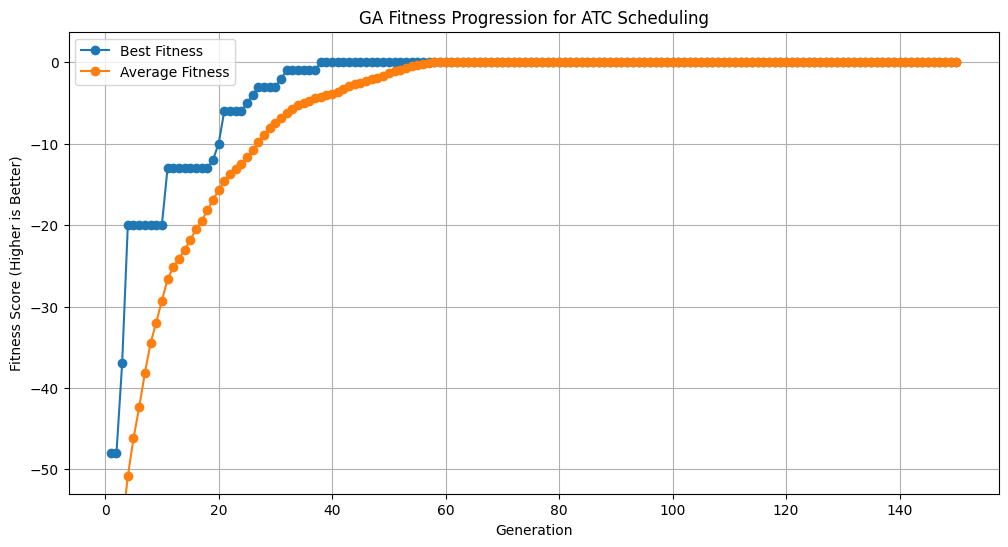

In [ ]:
def crossover(parent_1, parent_2, num_people):
    """
    Performs bit-level crossover between two parents.

    Args:
        parent_1 (list): First parent selected for crossover.
        parent_2 (list): Second parent selected for crossover.
        num_people (int): The number of people in the schedule.

    Returns:
        child (list): New child solution.
    """
    child = []
    for controller in range(num_people):
        controller_schedule = []
        for shift in range(21):
            bit = random.choice([parent_1[controller][shift], parent_2[controller][shift]])
            controller_schedule.append(bit)
        child.append(controller_schedule)
    return child

# Copy code above to run and plot this function
best_schedule, best_fitness, history, avg_history = genetic_algorithm(
        population_size=POPULATION_SIZE,
        num_people=NUM_PEOPLE,
        shifts_per_week=SHIFTS_PER_WEEK,
        shifts_per_day=SHIFTS_PER_DAY,
        generations=GENERATIONS,
        mutation_rate=MUTATION_RATE,
    ) # CHECK THE PARAMETERS!!!

print("\n" + "="*30)
print("      Best Schedule Found")
print("="*30)
if best_schedule:
    # Evaluate the final best schedule again to be certain of its fitness score
    final_check_fitness = evaluate_fitness(best_schedule, NUM_PEOPLE, SHIFTS_PER_WEEK, SHIFTS_PER_DAY)
    print_schedule(best_schedule, final_check_fitness)
    if abs(final_check_fitness - best_fitness) > 0.01:
            print(f"[Note] Final re-evaluated fitness {final_check_fitness:.2f} differs slightly from tracked fitness {best_fitness:.2f}")
else:
    print("\nNo suitable schedule found (best_schedule is None).")
    # Explain and show the plot
    print("\n" + "="*30)
    print("      Fitness Plot Explanation")
    print("="*30)
    print("The plot shows the fitness score evolution over generations:")
    print(" - 'Best Fitness': The fitness score of the absolute best schedule found in each generation.")
    print(" - 'Average Fitness': The average fitness score of all schedules in the population for each generation.")
    print("Ideally, both lines should trend upwards (towards 0 or positive values).")
    print("The gap between average and best fitness indicates population diversity.")
plot_fitness(history, avg_history)

- Step/Method you are replacing: Controller-level crossover

- Step/Method you are replacing it with: One-point crossover

- Interpret the results of this replacement: Similar to our previous implementation, we converged to a satisfactory solution. However, looking at the line plotting the best fitness score per generation, it appears have taken a fair bit longer to converge than the original implementation. I believe this is because the product of the one-point crossover caused more violations in regard to the rest requirement.


      Best Schedule Found

Schedule (Fitness: 0.00):
      Sun | Mon | Tue | Wed | Thu | Fri | Sat
      M A N M A N M A N M A N M A N M A N M A N
      ----------------------------------------------
ATC 1: 101 000 010 100 010 010 100
ATC 2: 010 010 010 010 010 101 000
ATC 3: 000 101 000 010 001 000 010
ATC 4: 000 010 000 001 000 000 010
ATC 5: 010 000 101 000 100 010 001
----------------------------------------------------


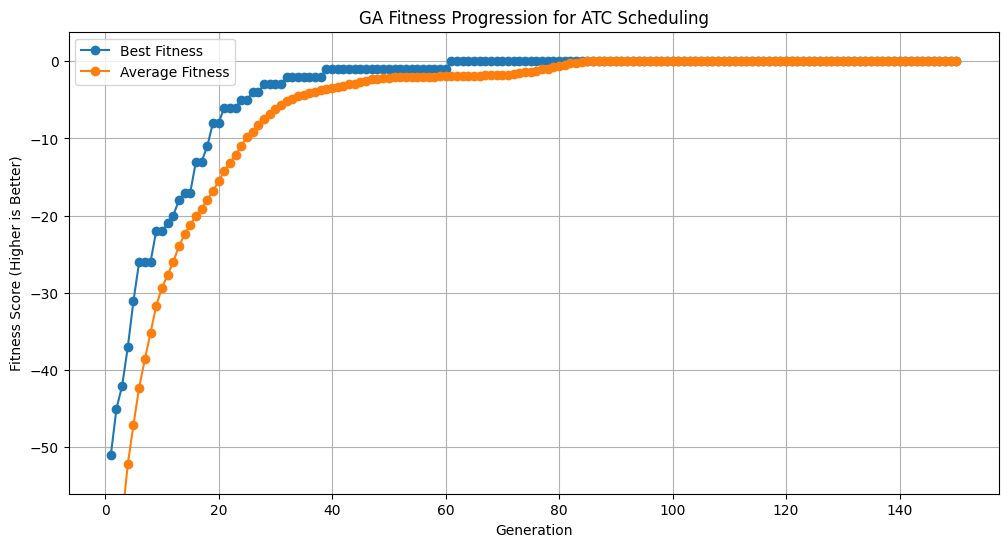

In [248]:
def crossover(parent_1, parent_2, num_people):
    """
    Performs one-point crossover for each collector's schedule between two parents.

    Args:
        parent_1 (list): First parent selected for crossover.
        parent_2 (list): Second parent selected for crossover.
        num_people (int): The number of people in the schedule.

    Returns:
        child (list): New child solution.
    """
    child = []
    for controller in range(num_people):
        point = random.randint(1, 20)
        child_schedule = parent_1[controller][:point] + parent_2[controller][point:]
        child.append(child_schedule)
    return child

# Copy code above to run and plot this function
best_schedule, best_fitness, history, avg_history = genetic_algorithm(
        population_size=POPULATION_SIZE,
        num_people=NUM_PEOPLE,
        shifts_per_week=SHIFTS_PER_WEEK,
        shifts_per_day=SHIFTS_PER_DAY,
        generations=GENERATIONS,
        mutation_rate=MUTATION_RATE,
    ) # CHECK THE PARAMETERS!!!

print("\n" + "="*30)
print("      Best Schedule Found")
print("="*30)
if best_schedule:
    # Evaluate the final best schedule again to be certain of its fitness score
    final_check_fitness = evaluate_fitness(best_schedule, NUM_PEOPLE, SHIFTS_PER_WEEK, SHIFTS_PER_DAY)
    print_schedule(best_schedule, final_check_fitness)
    if abs(final_check_fitness - best_fitness) > 0.01:
            print(f"[Note] Final re-evaluated fitness {final_check_fitness:.2f} differs slightly from tracked fitness {best_fitness:.2f}")
else:
    print("\nNo suitable schedule found (best_schedule is None).")
    # Explain and show the plot
    print("\n" + "="*30)
    print("      Fitness Plot Explanation")
    print("="*30)
    print("The plot shows the fitness score evolution over generations:")
    print(" - 'Best Fitness': The fitness score of the absolute best schedule found in each generation.")
    print(" - 'Average Fitness': The average fitness score of all schedules in the population for each generation.")
    print("Ideally, both lines should trend upwards (towards 0 or positive values).")
    print("The gap between average and best fitness indicates population diversity.")
plot_fitness(history, avg_history)